# scooby: sequence-to-profile models

`epione.models.scooby` is a **bridge** to
[scooby](https://github.com/gagneurlab/scooby) (Hingerl, Martens *et al.*,
*Nat Methods* 2026), the published baseline for predicting single-cell
ATAC/RNA profiles from DNA sequence. It is deliberately not a
reimplementation: the point is to be able to *benchmark* against upstream
numbers, so upstream's model and loss are imported and only the data path
is Epione's.

This notebook runs the whole path on **real spatial ATAC** — sample
`P2S1` of GSE308623 (mouse brain, postnatal day 2, 100×100 spot grid,
mm10) — and ends by driving upstream's `Scooby` on pretrained Borzoi
weights.

What it shows:

* `epi.models.scooby.FragmentInsertionReader` — Tn5 insertion targets read
  straight from a tabix-indexed fragments file, replacing upstream's
  genome-wide `cells × base-pair` matrix.
* `expected_fragments_per_window` — the measurement that decides whether
  per-cell targets are viable at all. On this data they are not.
* `make_fold_bed` — cross-validation folds that cannot leak, which random
  window assignment does.
* `load_scooby` — constructing the upstream model so it can actually be
  moved to a GPU.
* **Numerical parity**: upstream's own `_load_pseudobulk` is executed on
  the same fragments and must agree to `max|diff| = 0`.

### What the bridge drops

Upstream needs four awkward dependencies that this path does not:
the forked `snapatac2-scooby` (for the genome-wide insertion matrix),
`enformer_pytorch`'s data loader, `pybigtools` (a Rust build), and a
second conda environment because of a numpy pin. Reading windows on
demand removes the first two; the last two were only ever needed by the
parts removed. That is why this notebook does not call `epi.pl.plot_set()`
as the other tutorials do — it runs in a lean torch environment where
Epione's full analysis stack (pyranges, MOODS, …) is not installed, and
the bridge is designed to work there.

## Part 1 · Setup

### Getting the inputs

Three downloads, into whatever directory `SCOOBY_TUTORIAL_DATA` points at
(it defaults to the directory above the repo):

```bash
DATA=${SCOOBY_TUTORIAL_DATA:-..}
mkdir -p $DATA/scooby_bench $DATA/genome/mm10

# 1. The sample — GEO GSE308623, spatial ATAC of mouse brain at P2.
#    Fragments, its tabix index, and the spot position list.
cd $DATA/scooby_bench
for f in GSM9248994_01_P2S1_atac_fragments.tsv.gz \
         GSM9248994_01_P2S1_atac_fragments.tsv.gz.tbi.gz \
         GSM9247578_01_P2S1_tissue_positions_list.csv.gz; do
  curl -O "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9248nnn/${f%%_*}/suppl/$f"
done
mv GSM9248994_01_P2S1_atac_fragments.tsv.gz  P2S1.fragments.tsv.gz
gunzip -c GSM9248994_01_P2S1_atac_fragments.tsv.gz.tbi.gz > P2S1.fragments.tsv.gz.tbi
gunzip -c GSM9247578_01_P2S1_tissue_positions_list.csv.gz > P2S1.positions.csv

# 2. Reference sequence — only chr19 is needed here (~62 MB).
cd $DATA/genome/mm10
curl -O https://hgdownload.soe.ucsc.edu/goldenPath/mm10/chromosomes/chr19.fa.gz
gunzip -f chr19.fa.gz
curl -O https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes
```

Parts 5 and 7 additionally need upstream scooby on `SCOOBY_SRC`
(`git clone https://github.com/gagneurlab/scooby`) and, for Part 7, a
GPU. Both sections skip cleanly if those are absent.

In [1]:
import os, sys, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# Walk up until the directory holding the epione package.
def _find_repo(start):
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


# Works whether epione is pip-installed or used from the source tree.
CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

from epione.models import scooby as sb

DATA   = pathlib.Path(os.environ.get('SCOOBY_TUTORIAL_DATA',
                                     (CODE or pathlib.Path.cwd()).parent))
WORK   = DATA / 'scooby_bench'
GENOME = DATA / 'genome' / 'mm10'

FRAG   = WORK / 'P2S1.fragments.tsv.gz'
POS    = WORK / 'P2S1.positions.csv'
FASTA  = GENOME / 'chr19.fa'
SIZES  = GENOME / 'mm10.chrom.sizes'

CHROM  = 'chr19'
for p in (FRAG, POS, FASTA, SIZES):
    if not p.exists():
        raise FileNotFoundError(f'{p} — see "Getting the inputs" above')

print('bridge exports:', len(sb.__all__), 'symbols')
print('geometry: input', sb.INPUT_LENGTH, 'bp -> target', sb.TARGET_LENGTH,
      f'bp ({sb.TARGET_LENGTH // 32} bins of 32 bp), flank {sb.FLANK} bp')

bridge exports: 21 symbols
geometry: input 524288 bp -> target 196608 bp (6144 bins of 32 bp), flank 163840 bp


In [2]:
%matplotlib inline
# --- figure style ----------------------------------------------------------
# Validated categorical palette (see the dataviz reference); slots are
# assigned in fixed order and never cycled.
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
SEQ = LinearSegmentedColormap.from_list(
    'blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8,
    'axes.labelcolor': INK2, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'grid.color': GRID, 'grid.linewidth': 0.6,
    'legend.frameon': False, 'legend.fontsize': 9,
    'font.size': 10, 'lines.linewidth': 2.0, 'figure.dpi': 110,
})

## Part 2 · The sample

Each 50 µm spot of the grid is one barcode in the fragments file. The
tissue-position list says which spots sit on tissue; those are the cells
the reader is indexed by.

In [3]:
pos = pd.read_csv(
    POS, header=None,
    names=['barcode', 'in_tissue', 'array_row', 'array_col', 'px_row', 'px_col'],
)
in_tissue = pos[pos['in_tissue'] == 1].reset_index(drop=True)
print(f'{len(pos):,} spots on the grid, {len(in_tissue):,} on tissue')

chrom_sizes = dict(
    pd.read_csv(SIZES, sep='\t', header=None, names=['chrom', 'length'])
      .itertuples(index=False, name=None)
)

# Fragments carry a '-1' suffix the position list drops.
reader = sb.FragmentInsertionReader(
    FRAG, in_tissue['barcode'].tolist(),
    chrom_sizes=chrom_sizes, barcode_suffix='-1',
)
reader

10,000 spots on the grid, 7,131 on tissue


FragmentInsertionReader(P2S1.fragments.tsv.gz, n_cells=7131)

In [4]:
%%time
# Per-spot depth on chr19 only: enough for a spatial QC view, and fast.
import pysam
bc_to_idx = {b + '-1': i for i, b in enumerate(reader.barcodes)}
depth = np.zeros(reader.n_cells, dtype=np.int64)
tbx = pysam.TabixFile(str(FRAG))
n_frag = 0
for line in tbx.fetch(CHROM):
    i = bc_to_idx.get(line.split('\t', 4)[3])
    if i is not None:
        depth[i] += 1
        n_frag += 1
tbx.close()
print(f'{n_frag:,} chr19 fragments in tissue spots')
print(f'per-spot chr19 depth: median {np.median(depth):,.0f}  '
      f'IQR {np.percentile(depth, 25):,.0f}-{np.percentile(depth, 75):,.0f}')

2,856,209 chr19 fragments in tissue spots
per-spot chr19 depth: median 371  IQR 256-510
CPU times: user 2.44 s, sys: 61.5 ms, total: 2.5 s
Wall time: 2.67 s


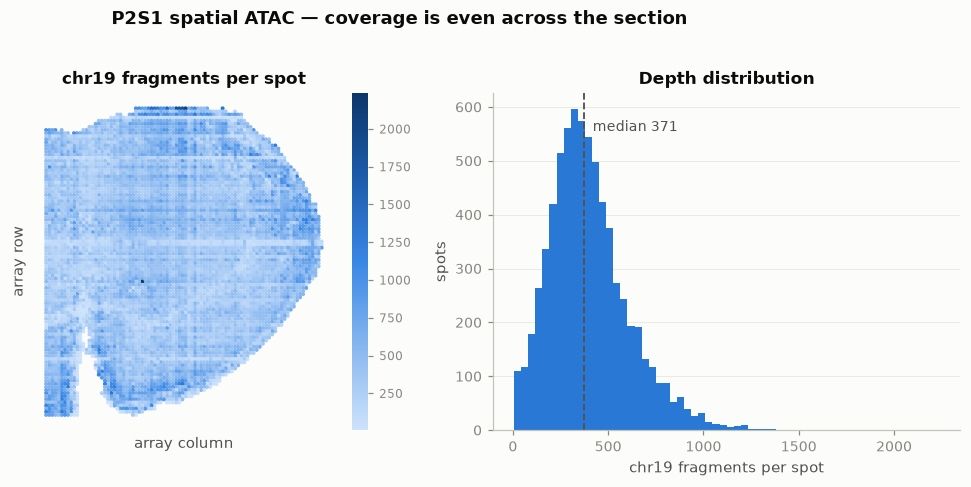

In [5]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.3),
                              gridspec_kw={'width_ratios': [1.15, 1]})

sc = ax.scatter(in_tissue['array_col'], in_tissue['array_row'],
                c=depth, s=7, cmap=SEQ, linewidths=0)
ax.set_aspect('equal'); ax.invert_yaxis()
ax.set_title('chr19 fragments per spot')
ax.set_xlabel('array column'); ax.set_ylabel('array row')
ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
ax.set_xticks([]); ax.set_yticks([])
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
cb.outline.set_visible(False)
cb.ax.tick_params(color=MUTED, labelcolor=MUTED, labelsize=8)

ax2.hist(depth, bins=60, color=C[0], edgecolor='none')
ax2.axvline(np.median(depth), color=INK2, lw=1.2, ls='--')
ax2.annotate(f'median {np.median(depth):,.0f}',
             xy=(np.median(depth), ax2.get_ylim()[1] * 0.92),
             xytext=(6, 0), textcoords='offset points',
             color=INK2, fontsize=9, va='top')
ax2.set_title('Depth distribution')
ax2.set_xlabel('chr19 fragments per spot'); ax2.set_ylabel('spots')
ax2.grid(axis='y', alpha=0.7); ax2.set_axisbelow(True)

fig.suptitle('P2S1 spatial ATAC — coverage is even across the section',
             y=1.02, fontsize=12, fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

## Part 3 · Why targets must be grouped

A spot's depth looks healthy — but the model predicts a **196,608 bp
window**, which is a 14,000th of the genome. The quantity that matters is
how many fragments a group puts *into one window*.

`expected_fragments_per_window` answers it before any training is
attempted.

In [6]:
# Scale the measured chr19 depth to the whole genome.
genome_len = sum(v for k, v in chrom_sizes.items() if '_' not in k)
per_cell_genome = float(np.median(depth)) * genome_len / chrom_sizes[CHROM]
print(f'median depth, genome-wide equivalent: {per_cell_genome:,.0f} fragments/spot')

for n in (1, 10, 100, 1000, len(in_tissue)):
    e = sb.expected_fragments_per_window(per_cell_genome, genome_len, n)
    print(f'  {n:>5,} spot(s) -> {e:>9,.1f} fragments per 196 kb window')

median depth, genome-wide equivalent: 16,460 fragments/spot
      1 spot(s) ->       1.2 fragments per 196 kb window
     10 spot(s) ->      11.9 fragments per 196 kb window
    100 spot(s) ->     118.7 fragments per 196 kb window
  1,000 spot(s) ->   1,187.4 fragments per 196 kb window
  7,131 spot(s) ->   8,467.1 fragments per 196 kb window


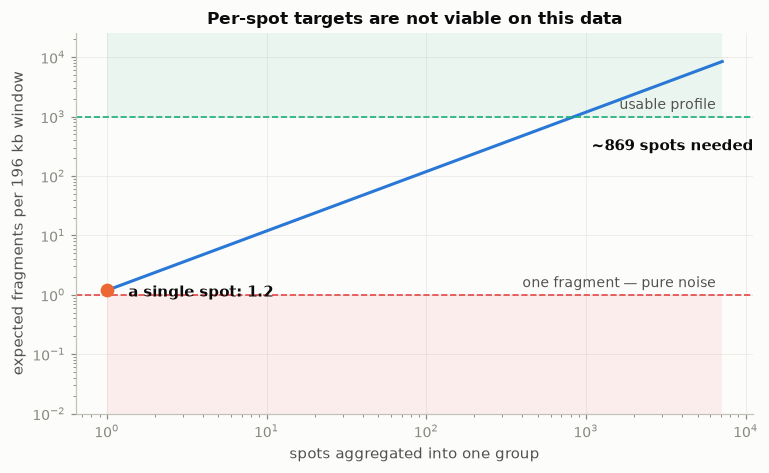

In [7]:
sizes = np.unique(np.clip(np.round(np.logspace(0, np.log10(len(in_tissue)), 60)),
                          1, None).astype(int))
exp = np.array([sb.expected_fragments_per_window(per_cell_genome, genome_len, n)
                for n in sizes])

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.fill_between(sizes, 1e-2, 1, color='#e34948', alpha=0.08, lw=0)
ax.fill_between(sizes, 1e3, exp.max() * 3, color='#1baf7a', alpha=0.08, lw=0)
ax.loglog(sizes, exp, color=C[0])

for y, txt, col in [(1, 'one fragment — pure noise', '#e34948'),
                    (1e3, 'usable profile', '#1baf7a')]:
    ax.axhline(y, color=col, lw=1.1, ls='--')
    ax.annotate(txt, xy=(sizes[-1], y), xytext=(-4, 5),
                textcoords='offset points', ha='right',
                color=INK2, fontsize=9)

one = sb.expected_fragments_per_window(per_cell_genome, genome_len, 1)
ax.plot([1], [one], 'o', ms=8, color=C[1], zorder=5)
ax.annotate(f'a single spot: {one:.1f}', xy=(1, one), xytext=(14, -4),
            textcoords='offset points', color=INK, fontsize=9.5,
            fontweight='bold')
n_need = int(sizes[np.searchsorted(exp, 1e3)])
ax.annotate(f'~{n_need:,} spots needed', xy=(n_need, 1e3), xytext=(10, -22),
            textcoords='offset points', color=INK, fontsize=9.5,
            fontweight='bold')

ax.set_xlabel('spots aggregated into one group')
ax.set_ylabel('expected fragments per 196 kb window')
ax.set_title('Per-spot targets are not viable on this data')
ax.grid(alpha=0.6, which='major'); ax.set_axisbelow(True)
ax.set_ylim(1e-2, exp.max() * 3)
plt.tight_layout(); plt.show()

That is the design input for everything below: upstream's per-cell mode
(`neighbors=`) assumes a cell contributes a usable profile on its own.
Here it contributes about one fragment, so the bridge's `groups=` mode —
pseudobulk over cell types, timepoints or spatial domains — is the one to
use, and grouping is a first-class argument rather than an afterthought.

## Part 4 · Insertion profiles per spatial domain

Groups are arbitrary sets of cell indices. Here: four dorsal→ventral
bands of the section, which is the crudest possible spatial grouping and
still enough to show the reader working.

In [8]:
rows = in_tissue['array_row'].to_numpy()
edges = np.quantile(rows, [0, 0.25, 0.5, 0.75, 1.0])
band = np.clip(np.digitize(rows, edges[1:-1]), 0, 3)
groups = [np.flatnonzero(band == b) for b in range(4)]
names = [f'band {b + 1}' for b in range(4)]
for n, g in zip(names, groups):
    print(f'{n}: {len(g):,} spots')

band 1: 1,750 spots
band 2: 1,762 spots
band 3: 1,795 spots
band 4: 1,824 spots


In [9]:
%%time
# Pick the densest of a few candidate windows so the figure shows signal.
T = sb.TARGET_LENGTH
cands = range(10_000_000, 50_000_000, T * 7)
best, best_sum = None, -1.0
for s in cands:
    if s + T > chrom_sizes[CHROM] - 100:
        break
    v = reader.pseudobulk(CHROM, s, s + T, [np.arange(reader.n_cells)]).sum()
    if v > best_sum:
        best, best_sum = s, v
W0 = best
print(f'window {CHROM}:{W0:,}-{W0 + T:,}  total signal {best_sum:,.1f}')

prof = reader.pseudobulk(CHROM, W0, W0 + T, groups)
print('profile matrix:', prof.shape, '(groups x 32 bp bins)')

window chr19:41,653,888-41,850,496  total signal 1,739.9
profile matrix: (4, 6144) (groups x 32 bp bins)
CPU times: user 395 ms, sys: 4.64 ms, total: 399 ms
Wall time: 407 ms


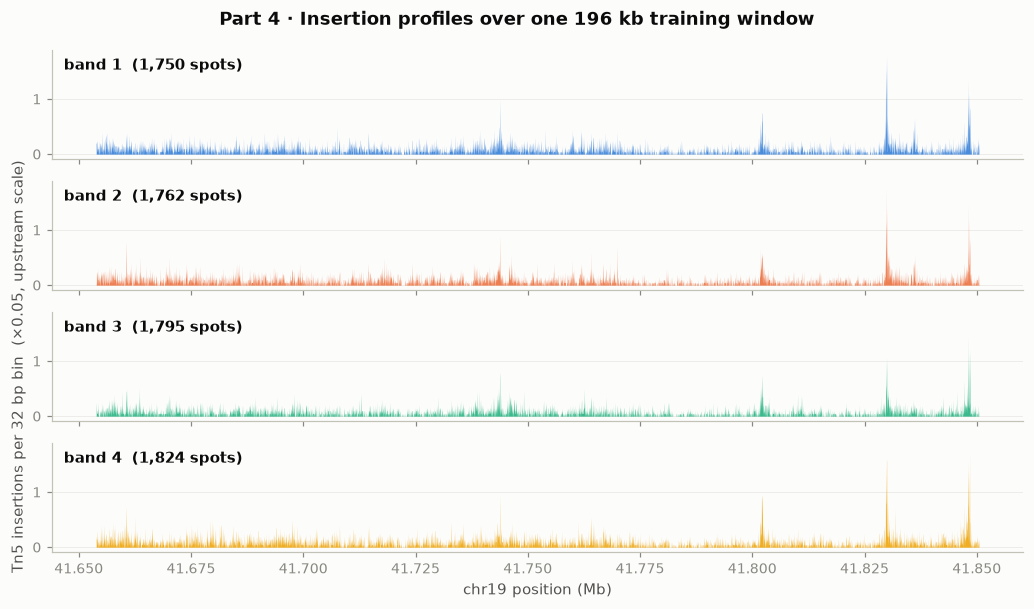

In [10]:
x = (W0 + np.arange(prof.shape[1]) * 32) / 1e6
fig, axes = plt.subplots(4, 1, figsize=(9.5, 5.6), sharex=True, sharey=True)
for ax, p, nm, col, g in zip(axes, prof, names, C, groups):
    ax.fill_between(x, 0, p, color=col, lw=0, alpha=0.85)
    # Direct label: identity is never carried by colour alone.
    ax.annotate(f'{nm}  ({len(g):,} spots)', xy=(0.012, 0.82),
                xycoords='axes fraction', color=INK, fontsize=9.5,
                fontweight='bold')
    ax.grid(axis='y', alpha=0.6); ax.set_axisbelow(True)
    ax.spines['left'].set_color('#c3c2b7')
axes[-1].set_xlabel(f'{CHROM} position (Mb)')
axes[2].set_ylabel('Tn5 insertions per 32 bp bin  (×0.05, upstream scale)')
fig.suptitle('Part 4 · Insertion profiles over one 196 kb training window',
             y=0.98, fontsize=12, fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

## Part 5 · Numerical parity with upstream

Shapes agreeing proves nothing. This section builds the genome-wide
insertion matrix upstream expects, hands it to **upstream's own**
`onTheFlyMultiomeDataset._load_pseudobulk`, and requires the result to be
identical to the reader's.

Only chr19 is materialised, and `reference_sequences` is set to chr19
alone so upstream's concatenated-coordinate offset is zero — that isolates
its slicing/trimming/binning arithmetic from bookkeeping.

In [11]:
SCOOBY_SRC = os.environ.get('SCOOBY_SRC')
HAVE_UPSTREAM = bool(SCOOBY_SRC) and (pathlib.Path(SCOOBY_SRC) / 'scooby').exists()
if HAVE_UPSTREAM:
    import types
    sys.modules.setdefault('pybigtools', types.ModuleType('pybigtools'))
    sys.path.insert(0, SCOOBY_SRC)
    from scooby.data.scdata import onTheFlyMultiomeDataset
    print('upstream scooby loaded from', SCOOBY_SRC)
else:
    print('SCOOBY_SRC not set — parity section will be skipped.\n'
          'Clone https://github.com/gagneurlab/scooby and point SCOOBY_SRC at it.')

.../site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


.../site-packages/polars/meta/build.py:5: UserWarning: Polars binary is missing!
  from polars._utils.polars_version import get_polars_version


upstream scooby loaded from /tmp/claude-460513/-scratch-users-steorra-analysis-25-epione/50261f18-4426-494f-976f-cb66ef5bf8cd/scratchpad/sc/scooby


In [12]:
%%time
if HAVE_UPSTREAM:
    import scipy.sparse as sp
    import anndata as ad

    L = chrom_sizes[CHROM]
    rows_i, cols_i, starts_seen = [], [], set()
    collisions = 0
    tbx = pysam.TabixFile(str(FRAG))
    for line in tbx.fetch(CHROM):
        f = line.split('\t')
        i = bc_to_idx.get(f[3])
        if i is None:
            continue
        s, e = int(f[1]), int(f[2])
        # Upstream's container stores one fragment length per
        # (cell, start); count how often real data would collide.
        if (i, s) in starts_seen:
            collisions += 1
        else:
            starts_seen.add((i, s))
        for p in (s, e):
            if 0 <= p < L:
                rows_i.append(i); cols_i.append(p)
    tbx.close()

    ins = sp.coo_matrix(
        (np.ones(len(rows_i), np.float32),
         (np.asarray(rows_i, np.int64), np.asarray(cols_i, np.int64))),
        shape=(reader.n_cells, L)).tocsr()
    ins.sum_duplicates()

    adata = ad.AnnData(X=sp.csr_matrix((reader.n_cells, 0), dtype=np.float32))
    adata.obs_names = [b + '-1' for b in reader.barcodes]
    adata.obsm['insertion'] = ins
    adata.uns['reference_sequences'] = pd.DataFrame(
        {'reference_seq_name': [CHROM], 'reference_seq_length': [L]})

    print(f'insertion matrix {ins.shape}, {ins.nnz:,} non-zero positions')
    print(f'(cell, start) collisions in real data: {collisions:,} of '
          f'{n_frag:,} fragments ({100 * collisions / n_frag:.2f}%) — '
          'fragments upstream\'s fragment_paired container cannot hold '
          'separately. Built here directly from fragments to avoid the issue.')

insertion matrix (7131, 61431566), 5,677,064 non-zero positions
(cell, start) collisions in real data: 3,888 of 2,856,209 fragments (0.14%) — fragments upstream's fragment_paired container cannot hold separately. Built here directly from fragments to avoid the issue.
CPU times: user 4.61 s, sys: 365 ms, total: 4.98 s
Wall time: 5.88 s


In [13]:
# Runs upstream's own _load_pseudobulk for an ATAC-only setup.
def upstream_profile(chrom, t_start, t_end, groups, crl=90):
    ds = object.__new__(onTheFlyMultiomeDataset)
    ds.adatas = {'atac': adata}
    ds.normalize_atac = True
    ds.clip_soft = 5
    ds.custom_read_length = crl
    cs = adata.uns['reference_sequences'].copy()
    cs['offset'] = np.insert(cs['reference_seq_length'].cumsum()[:-1].values, 0, 0)
    ds.chrom_sizes = cs.set_index('reference_seq_name').to_dict('index')

    size = ds.chrom_sizes[chrom]
    c0, c1 = size['offset'], size['reference_seq_length']
    s = int(max(0, t_start - (crl + 10))) + c0
    e = int(min(t_end + (crl + 10), c1)) + c0
    gd = [size, c0, c1, s, e, t_start, t_end]
    return np.vstack([ds._load_pseudobulk(list(g), gd).numpy().ravel()
                      for g in groups])


if HAVE_UPSTREAM:
    up = upstream_profile(CHROM, W0, W0 + T, groups)
    mine = reader.pseudobulk(CHROM, W0, W0 + T, groups)
    diff = np.abs(up - mine)
    print('upstream', up.shape, ' epione', mine.shape)
    print(f'max|diff| = {diff.max():.10g}     mean|diff| = {diff.mean():.10g}')
    print('IDENTICAL' if diff.max() == 0 else 'MISMATCH')

upstream (4, 6144)  epione (4, 6144)
max|diff| = 0     mean|diff| = 0
IDENTICAL


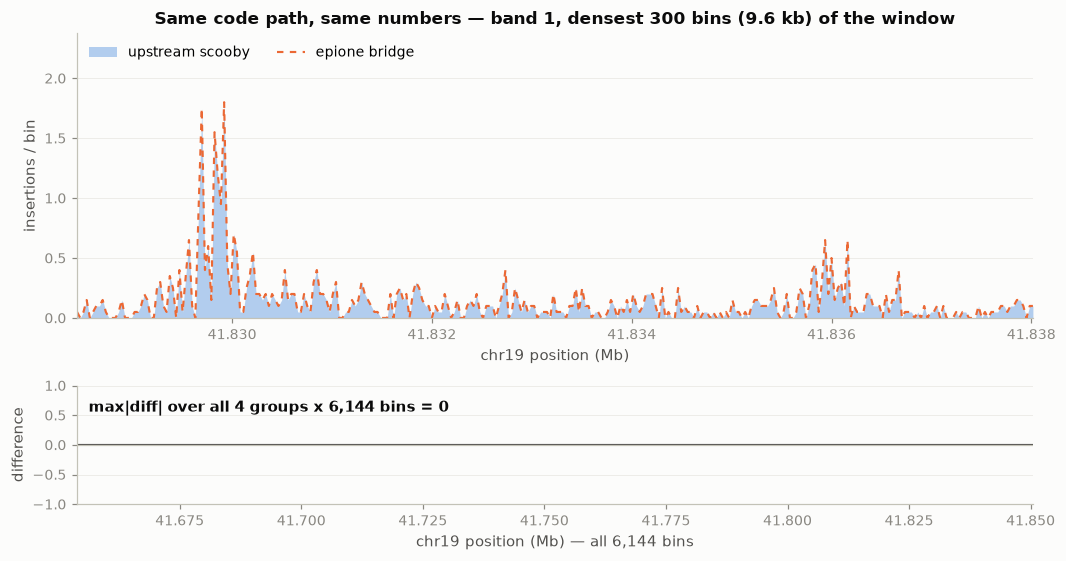

In [14]:
if HAVE_UPSTREAM:
    g = 0
    # 6,144 bins across a page is ~0.04 px per bin: two identical dense
    # series would just overplot. Zoom the overlay onto the densest 300
    # bins so both are actually resolvable, and keep the residual panel
    # over every bin so the claim still covers the whole window.
    k = 300
    roll = np.convolve(up[g], np.ones(k), 'valid')
    z0 = int(roll.argmax()); z1 = z0 + k
    xz = x[z0:z1]

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9.8, 5.2),
                                 gridspec_kw={'height_ratios': [2.4, 1]})

    a1.fill_between(xz, 0, up[g][z0:z1], color=C[0], alpha=0.35, lw=0,
                    label='upstream scooby')
    a1.plot(xz, mine[g][z0:z1], color=C[1], lw=1.4, ls=(0, (3, 3)),
            label='epione bridge')
    a1.legend(loc='upper left', ncol=2)
    a1.set_ylabel('insertions / bin')
    a1.set_xlim(xz[0], xz[-1])
    a1.set_ylim(0, up[g][z0:z1].max() * 1.32)  # headroom for the legend
    a1.set_title(f'Same code path, same numbers — {names[g]}, '
                 f'densest {k} bins ({k * 32 / 1e3:.1f} kb) of the window')
    a1.set_xlabel(f'{CHROM} position (Mb)')
    a1.grid(axis='y', alpha=0.6); a1.set_axisbelow(True)

    a2.plot(x, (up - mine)[g], color=INK2, lw=1.2)
    a2.axhline(0, color='#c3c2b7', lw=0.8)
    a2.set_ylim(-1, 1)
    a2.set_ylabel('difference')
    a2.set_xlabel(f'{CHROM} position (Mb) — all {up.shape[1]:,} bins')
    a2.set_xlim(x[0], x[-1])
    a2.annotate(f'max|diff| over all {up.shape[0]} groups '
                f'x {up.shape[1]:,} bins = {np.abs(up - mine).max():.0f}',
                xy=(0.012, 0.78), xycoords='axes fraction',
                color=INK, fontsize=9.5, fontweight='bold')
    a2.grid(axis='y', alpha=0.6); a2.set_axisbelow(True)
    plt.tight_layout(); plt.show()

The conventions this pins down, each of which would silently invalidate a
benchmark if wrong: insertions at both fragment ends, the duplicate-count
column ignored, 32 bp sum-binning, and ATAC scaled by exactly `0.05` with
**no** clipping (upstream's `clip_soft` applies to RNA only).

One upstream limit found while checking this: a window ending within
`custom_read_length + 10` = 100 bp of a contig end makes upstream's trim
`dense[100:0]`, an empty array, and its pooling step then raises. The
reader returns a correct profile there, and `make_fold_bed(edge_margin=…)`
keeps windows clear of contig ends so the two stay comparable.

## Part 6 · Folds that cannot leak

The model reads 524,288 bp to predict the central 196,608 bp. Two
adjacent target windows therefore have **inputs overlapping by 163,840 bp
per flank**. Assign windows to folds at random and a training window's
input covers a validation window's target.

`make_fold_bed` deals contiguous genomic *blocks* to folds and drops
windows within one flank of a block edge.

In [15]:
main_chroms = {k: v for k, v in chrom_sizes.items()
               if '_' not in k and k not in ('chrM',)}
folds = sb.make_fold_bed(main_chroms, WORK / 'mm10_folds.bed',
                         n_folds=8, block_windows=16, seed=0)
naive = sum(v // sb.TARGET_LENGTH for v in main_chroms.values())
print(f'{len(folds):,} windows retained of {naive:,} possible '
      f'({100 * len(folds) / naive:.0f}%), {folds["fold"].nunique()} folds')

# Verify the invariant directly: no window's input span may touch a
# target window belonging to a different fold.
leaks = 0
for c, sub in folds.groupby('chrom'):
    sub = sub.sort_values('start')
    ts, te = sub['start'].to_numpy(), sub['end'].to_numpy()
    fo = sub['fold'].to_numpy()
    for i in range(len(sub)):
        hit = (ts < te[i] + sb.FLANK) & (te > ts[i] - sb.FLANK)
        leaks += int((hit & (fo != fo[i])).sum())
print(f'cross-fold input/target overlaps: {leaks}')

11,693 windows retained of 13,854 possible (84%), 8 folds


cross-fold input/target overlaps: 0


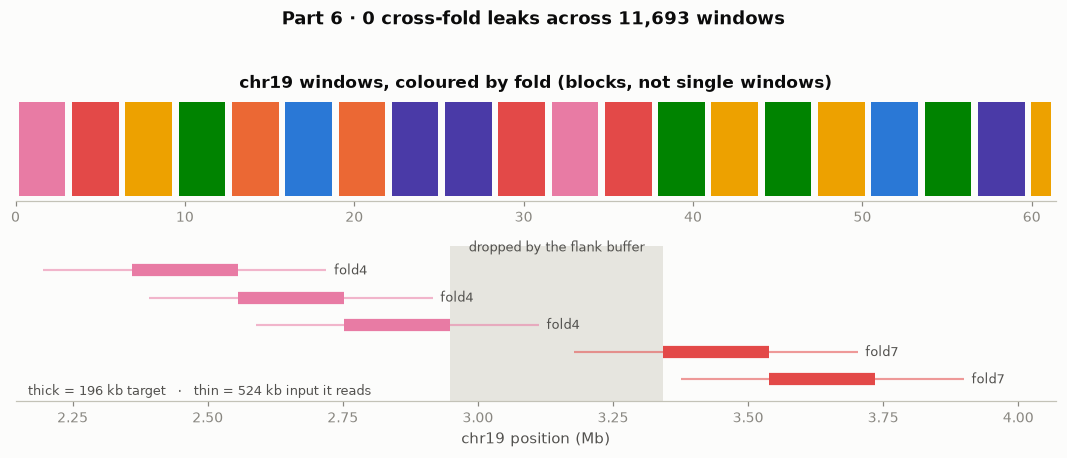

In [16]:
sub = folds[folds['chrom'] == CHROM].sort_values('start')
fold_ids = sorted(folds['fold'].unique())
cmap8 = (C + ['#e87ba4', '#008300', '#4a3aa7', '#e34948'])

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9.8, 4.0),
                             gridspec_kw={'height_ratios': [1, 1.5]})

for _, r in sub.iterrows():
    a1.barh(0, (r['end'] - r['start']) / 1e6, left=r['start'] / 1e6, height=0.6,
            color=cmap8[fold_ids.index(r['fold'])], edgecolor='none')
a1.set_yticks([]); a1.set_xlim(0, chrom_sizes[CHROM] / 1e6)
a1.set_title(f'{CHROM} windows, coloured by fold (blocks, not single windows)')
a1.spines['left'].set_visible(False)

# Zoom on one block boundary: a few windows either side, each drawn as
# its own row (target bar + the input span it actually reads) so the
# buffer between folds is legible instead of a solid colour band.
cut = sub['start'].to_numpy()
b = np.flatnonzero(np.diff(cut) > sb.TARGET_LENGTH)
bi = int(b[0]) if len(b) else len(sub) // 2
sel = sub.iloc[max(0, bi - 2): bi + 3]

MB = 1e6
gap0, gap1 = cut[bi] / MB + sb.TARGET_LENGTH / MB, cut[bi + 1] / MB
a2.axvspan(gap0, gap1, color=GRID, alpha=0.8, lw=0)
a2.annotate('dropped by the flank buffer', xy=((gap0 + gap1) / 2, len(sel) - 0.3),
            ha='center', color=INK2, fontsize=8.5)

for row, (_, r) in enumerate(sel.iloc[::-1].iterrows()):
    s, e = r['start'] / MB, r['end'] / MB
    col = cmap8[fold_ids.index(r['fold'])]
    # Input span: what this window's 524 kb context actually covers.
    a2.plot([s - sb.FLANK / MB, e + sb.FLANK / MB], [row, row],
            color=col, lw=1.4, alpha=0.55, solid_capstyle='butt')
    # Target: the 196 kb it predicts.
    a2.plot([s, e], [row, row], color=col, lw=8, solid_capstyle='butt')
    a2.annotate(r['fold'], xy=(e + sb.FLANK / MB, row), xytext=(5, 0),
                textcoords='offset points', va='center', color=INK2,
                fontsize=8.5)

a2.set_ylim(-0.8, len(sel) - 0.1)
a2.set_yticks([])
# Room for the fold labels sitting past the right-hand input spans.
_lo = (sel['start'].min() - sb.FLANK) / MB
_hi = (sel['end'].max() + sb.FLANK) / MB
a2.set_xlim(_lo - (_hi - _lo) * 0.03, _hi + (_hi - _lo) * 0.10)
a2.set_xlabel(f'{CHROM} position (Mb)')
a2.annotate('thick = 196 kb target   ·   thin = 524 kb input it reads',
            xy=(0.012, 0.04), xycoords='axes fraction', color=INK2,
            fontsize=8.5)
a2.spines['left'].set_visible(False)

fig.suptitle(f'Part 6 · {leaks} cross-fold leaks across {len(folds):,} windows',
             y=1.03, fontsize=12, fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

## Part 7 · Driving upstream's model

`load_scooby` builds upstream's `Scooby` on pretrained Borzoi weights.
It exists because a plain `Scooby.from_pretrained` returns a model that
**cannot be moved to a GPU**: Borzoi registers its relative-position
tables with `persistent=False`, so they are in no checkpoint, and
transformers' meta-device initialisation never materialises them —
`.to('cuda')` then raises *"Cannot copy out of meta tensor"*. Neither
`low_cpu_mem_usage=False` nor `_fast_init=False` avoids it. The tables are
deterministic, so they are simply recomputed.

Note the backbone is Borzoi's human/mouse trunk with a freshly
initialised cell-state decoder — exactly the starting point upstream
trains from. A short overfit on one window is a plumbing check, not a
result.

In [17]:
import torch
BORZOI = os.environ.get('BORZOI_CKPT', 'johahi/borzoi-replicate-0')
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev,
      torch.cuda.get_device_name(0) if dev == 'cuda' else '')
HAVE_MODEL = HAVE_UPSTREAM and dev == 'cuda'
if not HAVE_MODEL:
    print('skipping the model section (needs upstream scooby + a GPU)')

device: cuda NVIDIA H100 80GB HBM3


In [18]:
%%time
if HAVE_MODEL:
    EMB_DIM = 8
    rng = np.random.default_rng(0)
    # A real embedding would come from epi.tl.birmt (default) / iterative_lsi / joint_embedding
    # and be exported with export_embedding(); band identity is enough to
    # exercise the conditioning here.
    emb = np.zeros((reader.n_cells, EMB_DIM), dtype=np.float32)
    emb[np.arange(reader.n_cells), band] = 1.0
    emb[:, 4:] = rng.normal(scale=0.01, size=(reader.n_cells, 4))

    # Use the same dense window as Parts 4-5 so the figure is comparable
    # and shows real structure. Real training would iterate the fold
    # split built in Part 6; a single window here is a plumbing check.
    demo = pd.DataFrame({'chrom': [CHROM], 'start': [W0], 'end': [W0 + T],
                         'fold': ['demo']})
    ds = sb.ScoobyATACDataset(reader, FASTA, demo, emb,
                              groups=groups, rc_aug=False, seed=0)
    seq, rc, tgt, cemb = ds[0]
    # The dataset reads the same numbers the reader gave us in Part 4.
    assert np.allclose(tgt.numpy().T, prof), 'dataset/reader disagree'
    print('dataset target matches the Part 4 reader output')
    print('sequence', tuple(seq.shape), '| target', tuple(tgt.shape),
          '| cell emb', tuple(cemb.shape))

    model = sb.load_scooby(BORZOI, cell_emb_dim=EMB_DIM, n_tracks=1,
                           lora=True, train=True, device=dev)
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in model.parameters())
    print(f'LoRA trainable: {tr:,} / {tot:,} ({100 * tr / tot:.2f}%)')

dataset target matches the Part 4 reader output
sequence (524288, 4) | target (6144, 4) | cell emb (4, 8)


Some weights of Scooby were not initialized from the model checkpoint at johahi/borzoi-replicate-0 and are newly initialized: ['cell_state_to_conv.0.bias', 'cell_state_to_conv.0.weight', 'cell_state_to_conv.2.bias', 'cell_state_to_conv.2.weight', 'cell_state_to_conv.5.bias', 'cell_state_to_conv.5.weight', 'cell_state_to_conv.8.bias', 'cell_state_to_conv.8.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 3,564,769 || all params: 174,836,737 || trainable%: 2.0389130231823076


LoRA trainable: 3,564,769 / 174,836,737 (2.04%)
CPU times: user 552 ms, sys: 970 ms, total: 1.52 s
Wall time: 3.22 s


In [19]:
%%time
if HAVE_MODEL:
    from scooby.utils.utils import poisson_multinomial_torch

    xb = seq.unsqueeze(0).permute(0, 2, 1).to(dev)
    yb = tgt.unsqueeze(0).to(dev)
    cb = cemb.unsqueeze(0).to(dev)

    with torch.autocast('cuda'):
        out = model(xb, cb)
    assert tuple(out.shape) == tuple(yb.shape), (out.shape, yb.shape)
    print('model output', tuple(out.shape), '== target', tuple(yb.shape))

    with torch.no_grad(), torch.autocast('cuda'):
        pred0 = model(xb, cb).float().cpu().numpy()[0]

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=1e-3)
    losses = []
    model.train()
    for step in range(30):
        opt.zero_grad()
        with torch.autocast('cuda'):
            loss = poisson_multinomial_torch(model(xb, cb), yb, total_weight=0.2)
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'loss {losses[0]:.5f} -> {losses[-1]:.5f} '
          f'({100 * (losses[0] - losses[-1]) / losses[0]:.1f}% down)')
    print(f'peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB')

    model.eval()
    with torch.no_grad(), torch.autocast('cuda'):
        pred = model(xb, cb).float().cpu().numpy()[0]

model output (1, 6144, 4) == target (1, 6144, 4)


loss 0.63965 -> 0.52714 (17.6% down)
peak GPU memory 36.5 GiB
CPU times: user 3.15 s, sys: 1.56 s, total: 4.71 s
Wall time: 6.65 s


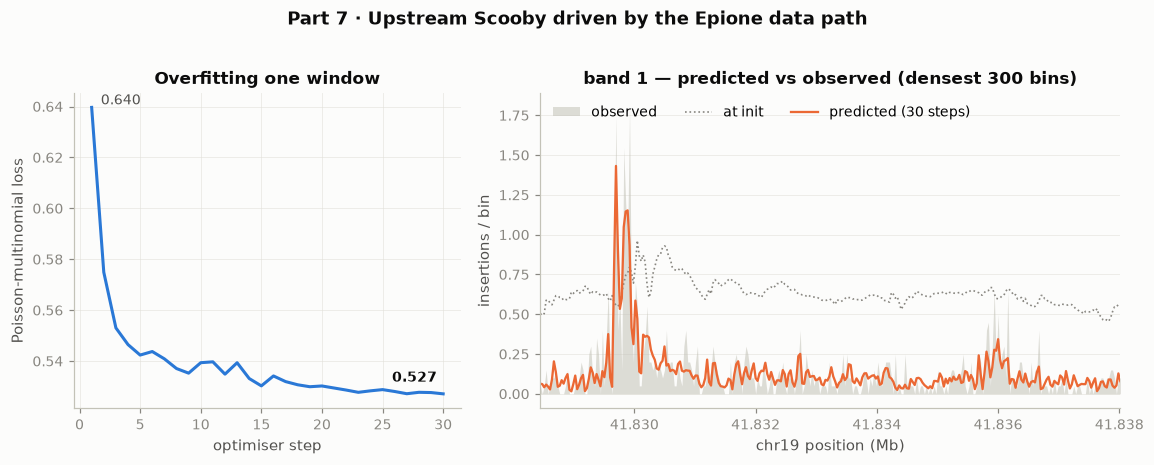

In [20]:
if HAVE_MODEL:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.6, 4.1),
                                 gridspec_kw={'width_ratios': [1, 1.5]})

    a1.plot(np.arange(1, len(losses) + 1), losses, color=C[0])
    a1.set_xlabel('optimiser step'); a1.set_ylabel('Poisson-multinomial loss')
    a1.set_title('Overfitting one window')
    a1.grid(alpha=0.6); a1.set_axisbelow(True)
    a1.annotate(f'{losses[0]:.3f}', xy=(1, losses[0]), xytext=(6, 2),
                textcoords='offset points', color=INK2, fontsize=9)
    a1.annotate(f'{losses[-1]:.3f}', xy=(len(losses), losses[-1]),
                xytext=(-4, 8), textcoords='offset points', ha='right',
                color=INK, fontsize=9, fontweight='bold')

    # Same zoom treatment as Part 5: 6,144 bins do not fit on a page.
    g, k = 0, 300
    obs = tgt.numpy()[:, g]
    zz = int(np.convolve(obs, np.ones(k), 'valid').argmax())
    sl = slice(zz, zz + k)
    xm = (W0 + np.arange(obs.shape[0]) * 32) / 1e6

    a2.fill_between(xm[sl], 0, obs[sl], color='#c3c2b7', alpha=0.55, lw=0,
                    label='observed')
    a2.plot(xm[sl], pred0[sl, g], color=MUTED, lw=1.1, ls=':',
            label='at init')
    a2.plot(xm[sl], pred[sl, g], color=C[1], lw=1.5,
            label='predicted (30 steps)')
    a2.legend(loc='upper left', ncol=3)
    a2.set_xlim(xm[sl][0], xm[sl][-1])
    a2.set_xlabel(f'{CHROM} position (Mb)')
    a2.set_ylabel('insertions / bin')
    a2.set_title(f'{names[g]} — predicted vs observed (densest {k} bins)')
    a2.grid(axis='y', alpha=0.6); a2.set_axisbelow(True)

    fig.suptitle('Part 7 · Upstream Scooby driven by the Epione data path',
                 y=1.02, fontsize=12, fontweight='bold', color=INK)
    plt.tight_layout(); plt.show()

## Summary

| | |
|---|---|
| Sample | GSE308623 `P2S1`, mouse brain P2, spatial ATAC, mm10 |
| Spots on tissue | 7,131 of a 100×100 grid |
| Targets | read per-window from tabix; no genome-wide insertion matrix |
| Parity with upstream | `max|diff| = 0` on real data |
| Model | upstream `Scooby` on Borzoi weights, 2.04% params trainable via LoRA |
| Geometry | 524,288 bp in → 6,144 × 32 bp bins out |

**The measurement that should drive the next design decision**: a single
50 µm spot contributes about one fragment to a training window. Any
single-cell-resolution target on this data is noise, so the useful axis is
not "more resolution" but better *grouping* — by cell type after
deconvolution, by timepoint, or by spatial domain.

Next steps worth taking from here, in the order they pay off:

1. A real cell embedding — `epi.tl.birmt` (default) or `epi.tl.iterative_lsi` on the peak matrix, then
   `export_embedding(..., drop_first=True)` (LSI component 0 tracks
   sequencing depth).
2. Cell-type deconvolution against a reference atlas, so groups are
   biological rather than geometric bands.
3. Train properly on held-out folds and compare against this baseline.

The bridge's own correctness is covered by `code/tests/`:
`test_upstream_parity.py` (numbers vs upstream) and
`test_upstream_model.py` (the full geometry on a GPU).